In [1]:
pip install -U mplhep

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, tempfile, subprocess
from coffea import processor
from coffea.nanoevents import NanoAODSchema, NanoEventsFactory
import matplotlib.pyplot as plt
import yaml

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities, scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.cosmicVeto import functions
from sidm.studies.dy_jets import function_dy

utilities.set_plot_style()
%matplotlib inline

In [3]:
channels=  [ 
    "cr_Zmumu_noLJ_displaced",
    "cr_Zmumu_noLJ_displaced_barrel",
    "cr_Zmumu_noLJ_displaced_endcap",
           ]

samples_separate = ["TTJets",
               "DYJetsToLL",
               "QCD",
               "Diboson",
              # "data"
              ]
samples = ["bgs", "data", "TTJets",
               "DYJetsToLL",
               "QCD",
               "Diboson",]
sum_hist= {}
for channel_name in channels:
    sum_hist[channel_name] = {}
for s in samples:
    if s == "data":
        list1= functions.get_data_files()
        list1 =  [x for x in list1 if "C" in x]
    elif s == "bgs":
        list1=[]
        for y in samples_separate:
            list2 = functions.get_bg_file_names(y)
            list1.extend(list2)
    else:
        list1 = functions.get_bg_file_names(s)
    for channel_name in channels:
        folder_name = f"OutputFiles/{channel_name}"
        sum_h= utilities.sum_hist(list1, folder_name)
        sum_hist[channel_name][s] = sum_h



In [4]:
ratio  = 6.616/62.061775847
def plot(histogram_list, channel_name, binning=1j):
    summed_QCD = sum_hist[channel_name]["QCD"]
    summed_TT = sum_hist[channel_name]["TTJets"]
    summed_DY = sum_hist[channel_name]["DYJetsToLL"]
    summed_DB = sum_hist[channel_name]["Diboson"]
    sum_data_all = sum_hist[channel_name]["data"]
    functions.plot_DataMC(histogram_list,
                      channel_name, 
                      summed_QCD, 
                      summed_TT, 
                      summed_DY, 
                      summed_DB, 
                      sum_data_all, 
                      ratio, binning=binning, 
                      file_name=f"{channel_name}_lj_pt", 
                         lumi=6.616)

muon_trkNumPixelHits


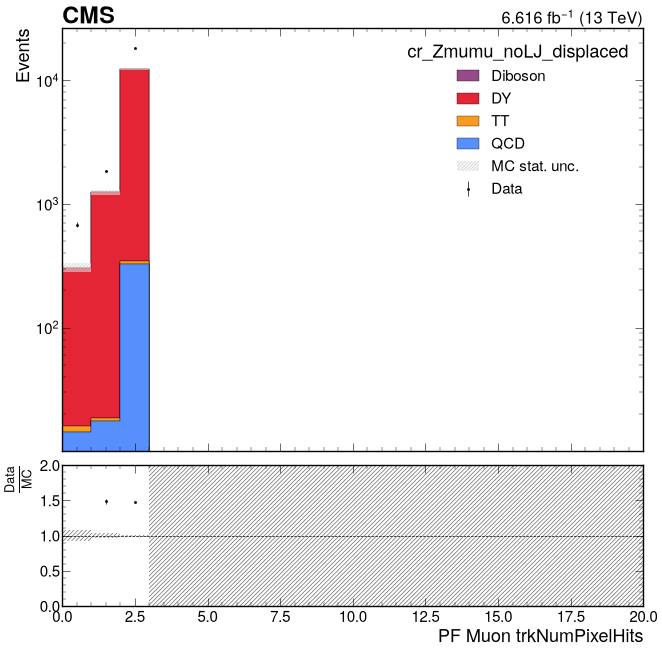

muon_trkNumPixelHits


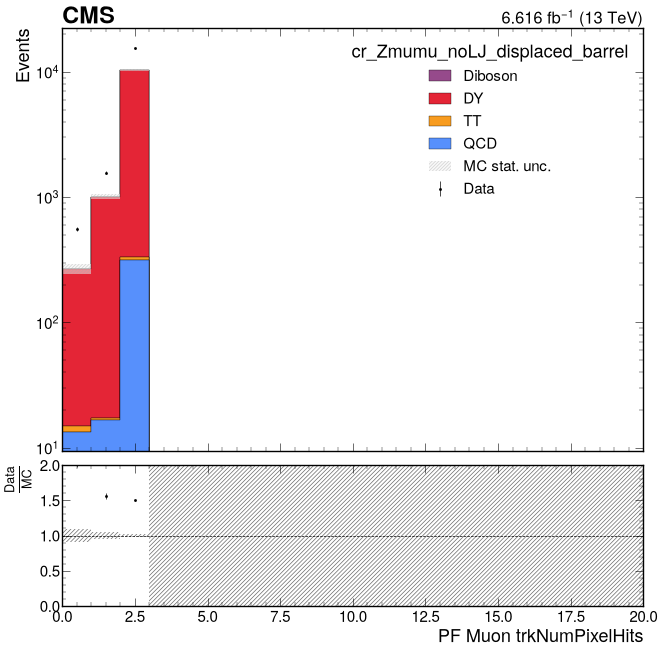

muon_trkNumPixelHits


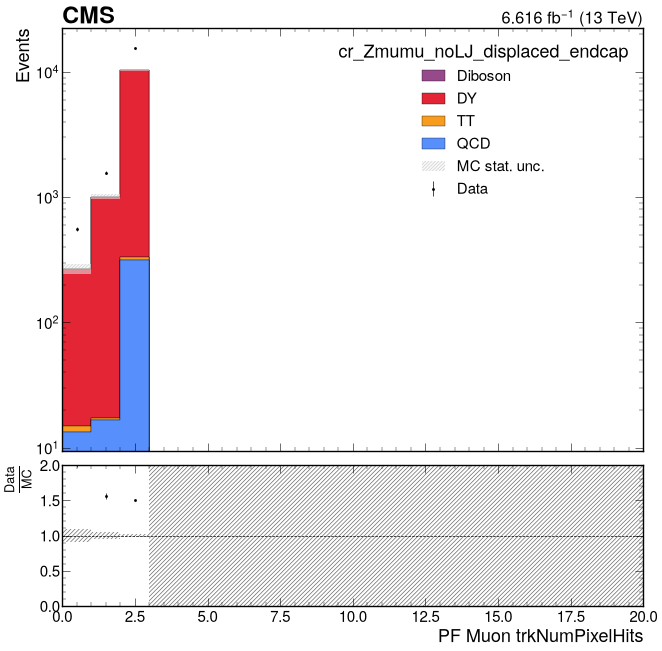

In [5]:
histogram_list = ["muon_trkNumPixelHits"]
plot(histogram_list, channels[0])
plot(histogram_list, channels[1])
plot(histogram_list, channels[2])